# Data Exploration

In [1242]:
import os 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tabulate import tabulate
from sklearn.metrics import precision_recall_curve, f1_score, accuracy_score, average_precision_score, precision_score, recall_score
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

SEED = 40

In [1243]:
df = pd.read_excel('covid_data.xlsx')

In [1244]:
df.head()

,id,sex,patient_type,entry_date,date_symptoms,date_died,intubed,pneumonia,age,pregnancy,...,inmsupr,hypertension,other_disease,cardiovascular,obesity,renal_chronic,tobacco,contact_other_covid,covid_res,icu
0,0dd249,Male,Outpatient,24-05-2020,18-05-2020,NaN,NaN,Yes,29,NaN,...,No,No,No,No,No,No,Yes,Yes,Negative,NaN
1,0957d9,Female,Outpatient,18-06-2020,16-06-2020,NaN,NaN,No,45,No,...,No,No,No,No,No,No,No,NaN,Negative,NaN
2,0ad2eb,Female,Outpatient,11-05-2020,11-05-2020,NaN,NaN,No,25,No,...,No,No,No,No,No,No,No,Yes,Negative,NaN
3,1646ba,Female,Outpatient,24-06-2020,19-06-2020,NaN,NaN,No,11,No,...,No,No,No,No,No,No,No,Yes,Positive,NaN
4,1e31dd,Male,Outpatient,17-05-2020,16-05-2020,NaN,NaN,No,28,NaN,...,No,No,No,No,No,No,No,Yes,Negative,NaN


In [1245]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   id                   10000 non-null  str  
 1   sex                  10000 non-null  str  
 2   patient_type         10000 non-null  str  
 3   entry_date           10000 non-null  str  
 4   date_symptoms        10000 non-null  str  
 5   date_died            639 non-null    str  
 6   intubed              2137 non-null   str  
 7   pneumonia            9999 non-null   str  
 8   age                  10000 non-null  int64
 9   pregnancy            4841 non-null   str  
 10  diabetes             9965 non-null   str  
 11  copd                 9969 non-null   str  
 12  asthma               9968 non-null   str  
 13  inmsupr              9966 non-null   str  
 14  hypertension         9968 non-null   str  
 15  other_disease        9956 non-null   str  
 16  cardiovascular       9966 non-null

In [1246]:
df.describe()

,age
count,10000.000000
mean,42.772600
std,19.634629
min,-67.000000
25%,31.000000
50%,41.000000
75%,53.000000
max,856.000000


In [1247]:
null_counts = df.isnull().sum()
null_counts

id                        0
sex                       0
patient_type              0
entry_date                0
date_symptoms             0
date_died              9361
intubed                7863
pneumonia                 1
age                       0
pregnancy              5159
diabetes                 35
copd                     31
asthma                   32
inmsupr                  34
hypertension             32
other_disease            44
cardiovascular           34
obesity                  31
renal_chronic            33
tobacco                  34
contact_other_covid    3107
covid_res                 0
icu                    7863
dtype: int64

In [1248]:
df[(df['age']>100) | (df['age']<0)]

,id,sex,patient_type,entry_date,date_symptoms,date_died,intubed,pneumonia,age,pregnancy,...,inmsupr,hypertension,other_disease,cardiovascular,obesity,renal_chronic,tobacco,contact_other_covid,covid_res,icu
6535,1be176,Male,Outpatient,06-06-2020,05-06-2020,NaN,NaN,No,107,NaN,...,No,No,No,No,No,No,No,Yes,Negative,NaN
9630,1c55e6,Male,Inpatient,11-04-2020,10-04-2020,NaN,No,Yes,311,NaN,...,No,No,No,No,No,No,Yes,NaN,Negative,No
9634,1230b6,Male,Outpatient,25-05-2020,20-05-2020,NaN,NaN,No,-56,NaN,...,No,No,No,No,No,No,No,Yes,Positive,NaN
9772,1e8395,Male,Outpatient,07-05-2020,02-05-2020,NaN,NaN,No,483,NaN,...,No,No,No,No,No,No,No,No,Positive,NaN
9812,08a4d0,Female,Outpatient,07-05-2020,04-05-2020,NaN,NaN,No,856,No,...,No,Yes,No,No,No,No,No,No,Negative,NaN
9848,05172f,Male,Outpatient,26-05-2020,20-05-2020,NaN,NaN,No,-48,NaN,...,No,No,No,No,No,No,Yes,NaN,Awaiting Results,NaN
9910,08d6d0,Male,Outpatient,25-06-2020,24-06-2020,NaN,NaN,No,280,NaN,...,No,No,No,No,No,No,No,Yes,Awaiting Results,NaN
9980,15423d,Male,Outpatient,06-05-2020,30-04-2020,NaN,NaN,No,155,NaN,...,No,No,No,No,No,No,No,Yes,Negative,NaN
9986,0b62c3,Male,Outpatient,23-06-2020,19-06-2020,NaN,NaN,No,-67,NaN,...,No,Yes,No,No,No,No,No,Yes,Negative,NaN


In [1249]:
df = df[(df["age"] >= 0) & (df["age"] <= 120)]

In [1250]:
df['id'].nunique()

9986

In [1251]:
df['id'] = df.index

In [1252]:
df.columns


Index(['id', 'sex', 'patient_type', 'entry_date', 'date_symptoms', 'date_died',
       'intubed', 'pneumonia', 'age', 'pregnancy', 'diabetes', 'copd',
       'asthma', 'inmsupr', 'hypertension', 'other_disease', 'cardiovascular',
       'obesity', 'renal_chronic', 'tobacco', 'contact_other_covid',
       'covid_res', 'icu'],
      dtype='str')

In [1253]:
date_col = ['entry_date', 'date_symptoms', 'date_died']
cat_col = [ 'sex', 'patient_type', 'intubed', 'pneumonia', 'pregnancy', 'diabetes', 'copd',
       'asthma', 'inmsupr', 'hypertension', 'other_disease', 'cardiovascular',
       'obesity', 'renal_chronic', 'tobacco', 'contact_other_covid',
       'covid_res', 'icu']
for col in date_col:
    df[col] = pd.to_datetime(df[col], dayfirst=True)

In [1254]:
df.head(3)

,id,sex,patient_type,entry_date,date_symptoms,date_died,intubed,pneumonia,age,pregnancy,...,inmsupr,hypertension,other_disease,cardiovascular,obesity,renal_chronic,tobacco,contact_other_covid,covid_res,icu
0,0,Male,Outpatient,2020-05-24,2020-05-18,NaT,NaN,Yes,29,NaN,...,No,No,No,No,No,No,Yes,Yes,Negative,NaN
1,1,Female,Outpatient,2020-06-18,2020-06-16,NaT,NaN,No,45,No,...,No,No,No,No,No,No,No,NaN,Negative,NaN
2,2,Female,Outpatient,2020-05-11,2020-05-11,NaT,NaN,No,25,No,...,No,No,No,No,No,No,No,Yes,Negative,NaN


In [1255]:
np.max(df['entry_date']-df['date_symptoms'])

Timedelta('38 days 00:00:00')

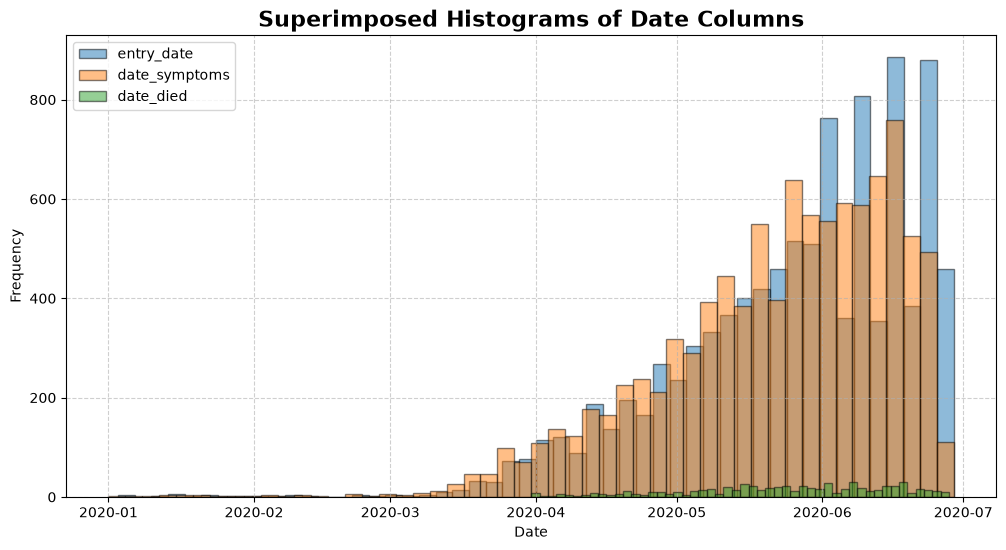

In [1256]:
for col in date_col:
    df[col] = pd.to_datetime(df[col], errors="coerce")

plt.figure(figsize=(12, 6))


for col in date_col:
    df[col].hist(
        bins=50,
        alpha=0.5,             
        label=col,
        edgecolor="black"
    )

plt.title("Superimposed Histograms of Date Columns", fontsize=16, fontweight="bold")
plt.xlabel("Date")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()


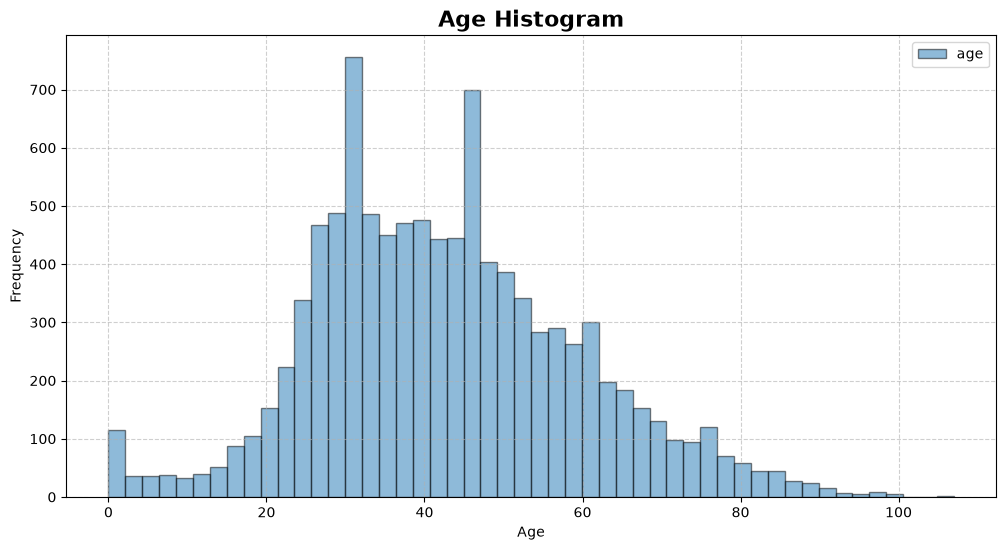

In [1257]:
plt.figure(figsize=(12, 6))

df['age'].hist(
    bins=50,
    alpha=0.5,             
    label='age',
    edgecolor="black"
)

plt.title("Age Histogram", fontsize=16, fontweight="bold")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

In [1258]:
df.describe()

,id,entry_date,date_symptoms,date_died,age
count,9992.000000,9992,9992,639,9992.000000
mean,4995.639311,2020-05-25 16:27:11.385108,2020-05-22 01:03:59.231385,2020-05-24 11:20:33.802817,42.615292
min,0.000000,2020-01-03 00:00:00,2020-01-01 00:00:00,2020-03-31 00:00:00,0.000000
25%,2497.750000,2020-05-11 00:00:00,2020-05-07 00:00:00,2020-05-11 00:00:00,31.000000
50%,4995.500000,2020-05-30 00:00:00,2020-05-26 00:00:00,2020-05-26 00:00:00,41.000000
75%,7493.250000,2020-06-15 00:00:00,2020-06-11 00:00:00,2020-06-10 00:00:00,53.000000
max,9999.000000,2020-06-29 00:00:00,2020-06-29 00:00:00,2020-06-28 00:00:00,107.000000
std,2884.821221,NaN,NaN,NaN,16.825870


### Review Each Feature value counts

          sex
sex          
Female   4763
Femalee   111
Male     5066
Males      52
              patient_type
patient_type              
Inpatient             2139
Outpatient            7853
         intubed
intubed         
No          1955
Yes          181
           pneumonia
pneumonia           
No              8445
Yes             1546
           pregnancy
pregnancy           
No              4770
Yes               70
          diabetes
diabetes          
No            8738
Yes           1219
      copd
copd      
No    9805
Yes    156
        asthma
asthma        
No        9639
Yes        321
         inmsupr
inmsupr         
No          9785
Yes          173
              hypertension
hypertension              
No                    8372
Yes                   1588
               other_disease
other_disease               
No                      9638
Yes                      310
                cardiovascular
cardiovascular                
No                        9747
Yes    

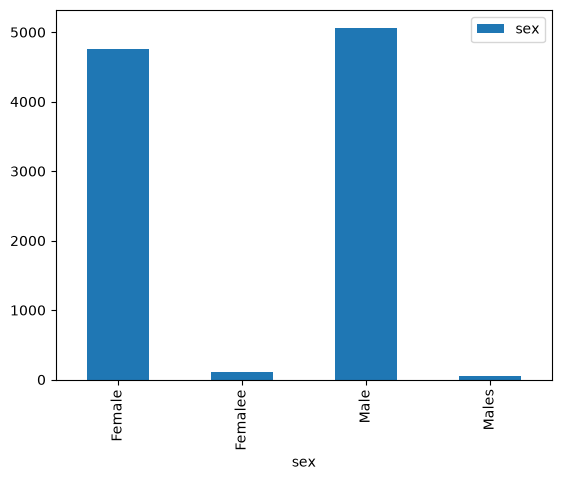

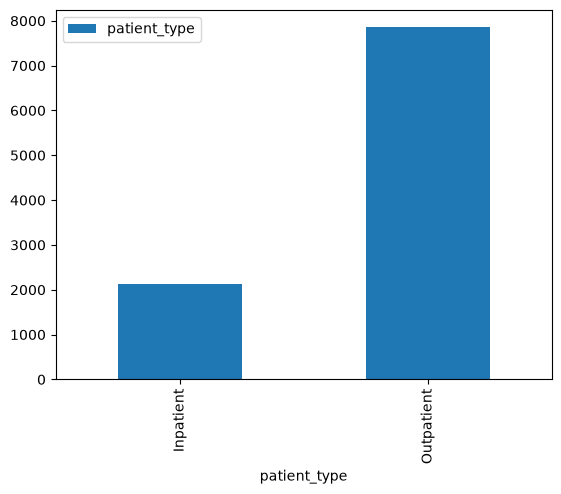

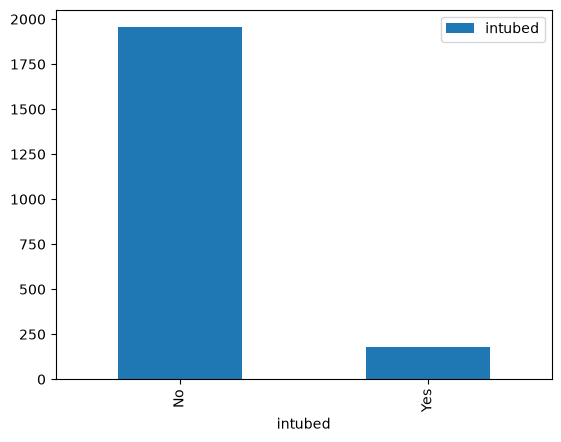

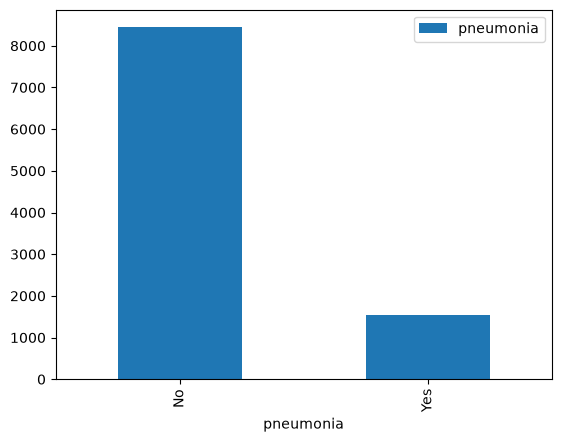

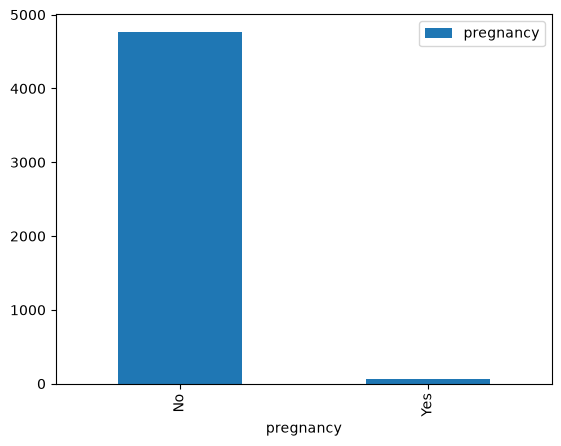

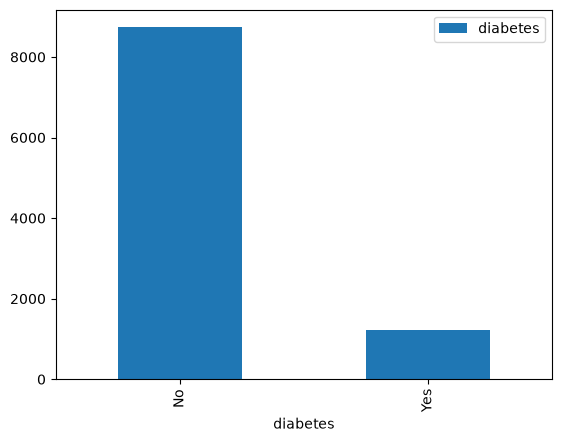

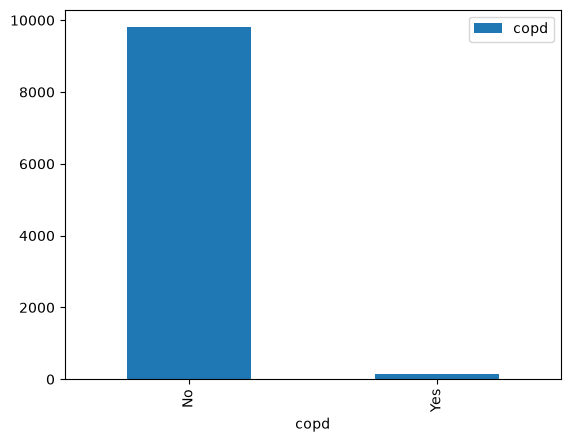

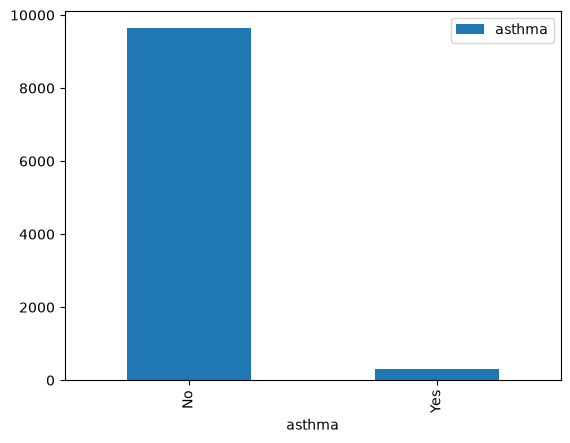

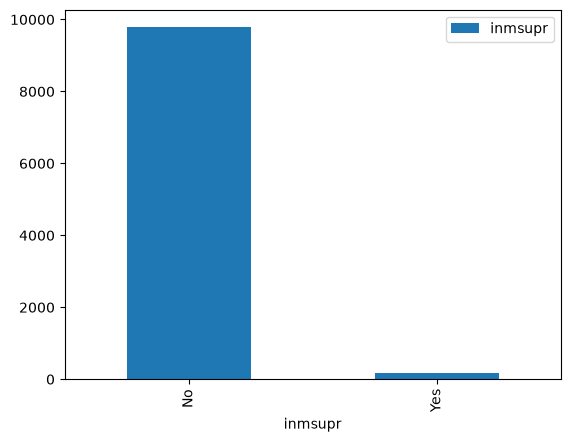

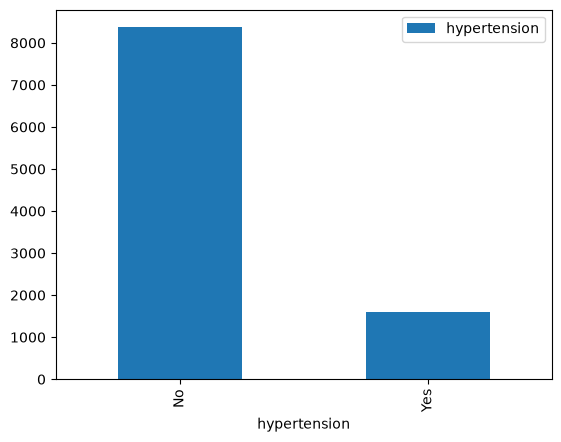

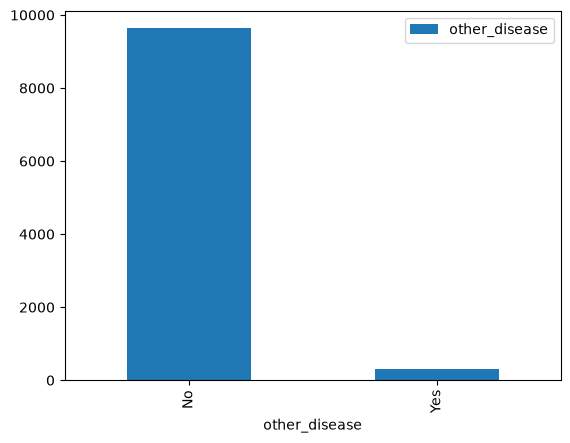

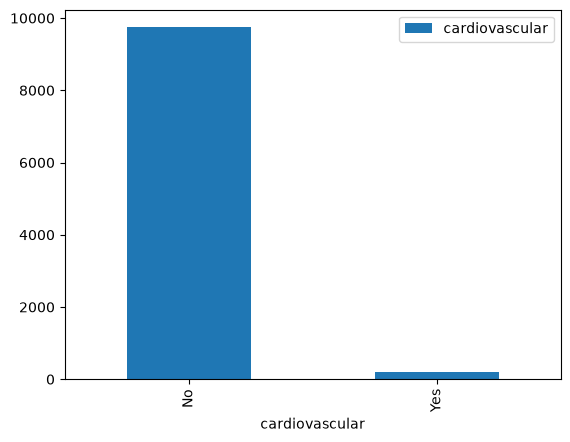

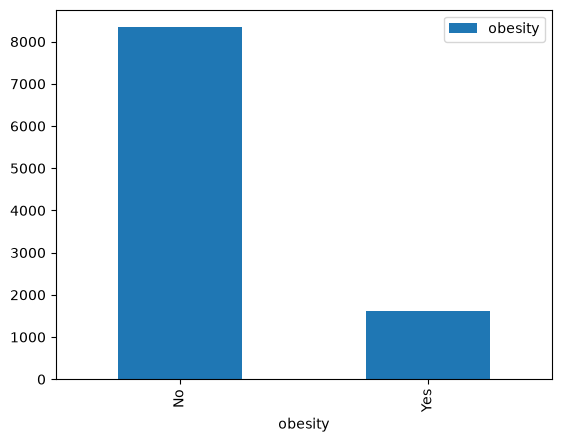

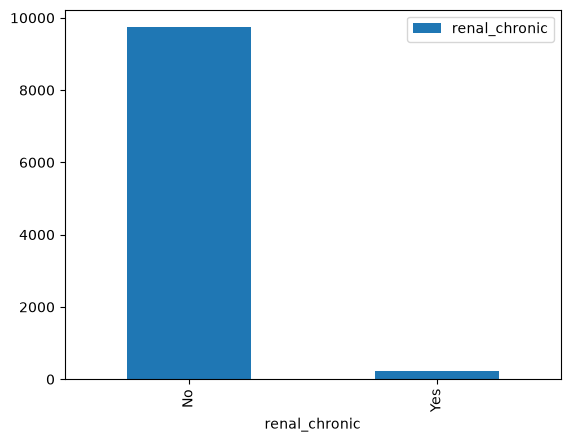

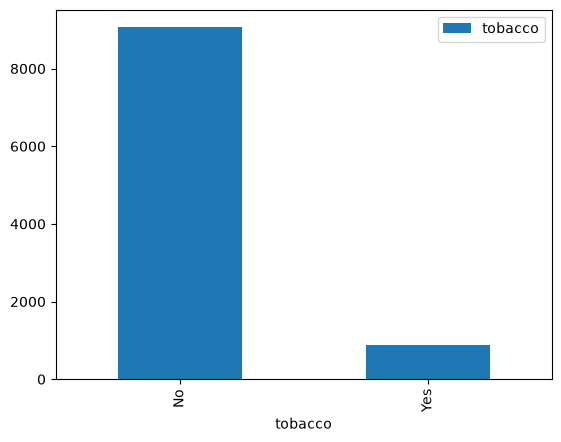

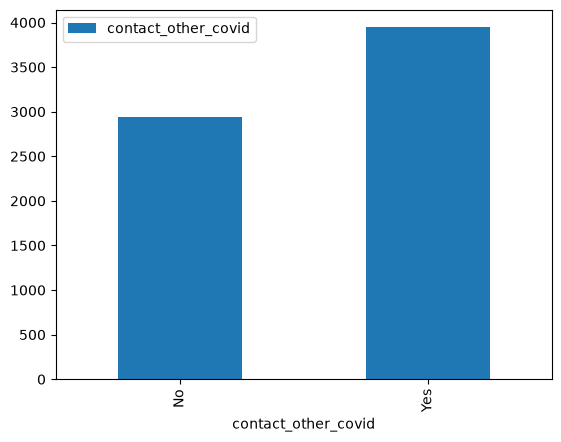

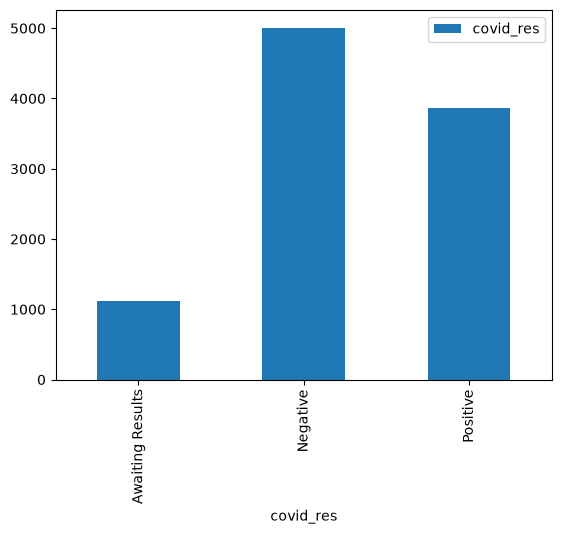

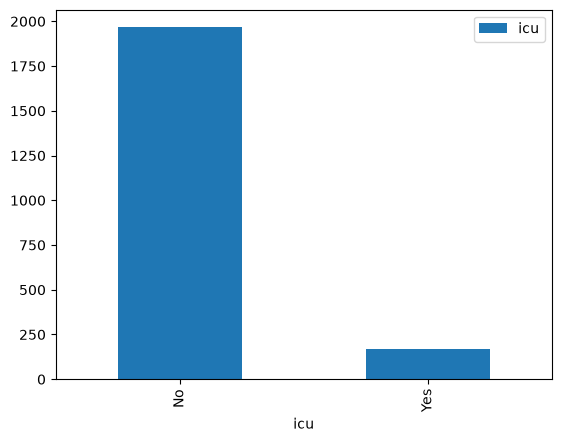

In [1260]:
for col in cat_col:
    print(f'{df.groupby(col)[col].count().to_frame()}')
    df.groupby(col)[col].count().to_frame().plot(kind='bar')

In [1261]:
def change_sex(current_sex):
    if current_sex == 'Male' or current_sex == 'Female':
        return current_sex
    elif current_sex == 'Males':
        return "Male"
    elif current_sex == 'Femalee':
        return 'Female'

df['sex'] = df['sex'].apply(change_sex)

In [1262]:
df[df['patient_type']=='Inpatient'].groupby('icu')['icu'].count()

icu
No     1967
Yes     169
Name: icu, dtype: int64

In [1263]:
df.groupby('icu')['icu'].count()

icu
No     1967
Yes     169
Name: icu, dtype: int64

In [1264]:
df[df['sex']=='Female'].groupby('pregnancy')['pregnancy'].count()

pregnancy
No     4770
Yes      70
Name: pregnancy, dtype: int64

In [1265]:
df[df['intubed']=='Yes'].groupby('covid_res')['covid_res'].count()

covid_res
Awaiting Results     19
Negative             48
Positive            114
Name: covid_res, dtype: int64

In [1266]:
df['symptom_duration'] = (df['entry_date']-df['date_symptoms']).dt.days
df['entry_to_death'] = (df['date_died']-df['entry_date']).dt.days
df['symptom_to_death'] = (df['date_died']-df['date_symptoms']).dt.days
df["died"] = df["date_died"].notna().map({True: "Yes", False: "No"})


In [1267]:
df.describe()

,id,entry_date,date_symptoms,date_died,age,symptom_duration,entry_to_death,symptom_to_death
count,9992.000000,9992,9992,639,9992.000000,9992.000000,639.000000,639.000000
mean,4995.639311,2020-05-25 16:27:11.385108,2020-05-22 01:03:59.231385,2020-05-24 11:20:33.802817,42.615292,3.641113,7.133020,11.244131
min,0.000000,2020-01-03 00:00:00,2020-01-01 00:00:00,2020-03-31 00:00:00,0.000000,0.000000,-2.000000,0.000000
25%,2497.750000,2020-05-11 00:00:00,2020-05-07 00:00:00,2020-05-11 00:00:00,31.000000,1.000000,2.000000,5.000000
50%,4995.500000,2020-05-30 00:00:00,2020-05-26 00:00:00,2020-05-26 00:00:00,41.000000,3.000000,5.000000,10.000000
75%,7493.250000,2020-06-15 00:00:00,2020-06-11 00:00:00,2020-06-10 00:00:00,53.000000,5.000000,11.000000,15.000000
max,9999.000000,2020-06-29 00:00:00,2020-06-29 00:00:00,2020-06-28 00:00:00,107.000000,38.000000,49.000000,49.000000
std,2884.821221,NaN,NaN,NaN,16.825870,3.245147,7.146441,7.796181


In [1269]:
df[df['tobacco']!=np.nan]

,id,sex,patient_type,entry_date,date_symptoms,date_died,intubed,pneumonia,age,pregnancy,...,obesity,renal_chronic,tobacco,contact_other_covid,covid_res,icu,symptom_duration,entry_to_death,symptom_to_death,died
0,0,Male,Outpatient,2020-05-24,2020-05-18,NaT,NaN,Yes,29,NaN,...,No,No,Yes,Yes,Negative,NaN,6,NaN,NaN,No
1,1,Female,Outpatient,2020-06-18,2020-06-16,NaT,NaN,No,45,No,...,No,No,No,NaN,Negative,NaN,2,NaN,NaN,No
2,2,Female,Outpatient,2020-05-11,2020-05-11,NaT,NaN,No,25,No,...,No,No,No,Yes,Negative,NaN,0,NaN,NaN,No
3,3,Female,Outpatient,2020-06-24,2020-06-19,NaT,NaN,No,11,No,...,No,No,No,Yes,Positive,NaN,5,NaN,NaN,No
4,4,Male,Outpatient,2020-05-17,2020-05-16,NaT,NaN,No,28,NaN,...,No,No,No,Yes,Negative,NaN,1,NaN,NaN,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9995,Male,Outpatient,2020-06-16,2020-06-15,NaT,NaN,No,43,NaN,...,No,No,No,No,Negative,NaN,1,NaN,NaN,No
9996,9996,Male,Inpatient,2020-05-05,2020-04-24,NaT,No,Yes,31,NaN,...,No,No,No,No,Positive,No,11,NaN,NaN,No
9997,9997,Male,Outpatient,2020-05-26,2020-05-22,NaT,NaN,No,24,NaN,...,No,No,No,Yes,Negative,NaN,4,NaN,NaN,No
9998,9998,Female,Outpatient,2020-05-08,2020-05-05,NaT,NaN,No,42,No,...,No,No,No,Yes,Negative,NaN,3,NaN,NaN,No


In [1270]:
df.loc[df['sex']== 'Male', 'pregnancy'] = 'No'
df.loc[df['sex']== 'Female', 'pregnancy'] = 'No'


In [1271]:
df['intubed'] = df['intubed'].fillna('No')
df['icu'] = df['icu'].fillna('No')

In [1272]:
df.info()

<class 'pandas.DataFrame'>
Index: 9990 entries, 0 to 9999
Data columns (total 27 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   id                   9990 non-null   int64         
 1   sex                  9990 non-null   str           
 2   patient_type         9990 non-null   str           
 3   entry_date           9990 non-null   datetime64[us]
 4   date_symptoms        9990 non-null   datetime64[us]
 5   date_died            637 non-null    datetime64[us]
 6   intubed              9990 non-null   str           
 7   pneumonia            9989 non-null   str           
 8   age                  9990 non-null   int64         
 9   pregnancy            9990 non-null   str           
 10  diabetes             9955 non-null   str           
 11  copd                 9959 non-null   str           
 12  asthma               9958 non-null   str           
 13  inmsupr              9956 non-null   str         

In [1273]:
df_covid_result_present = df[(df['covid_res']== 'Positive')|(df['covid_res']=='Negative')].copy()

In [1274]:
df_covid_result_present.info()

<class 'pandas.DataFrame'>
Index: 8870 entries, 0 to 9999
Data columns (total 27 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   id                   8870 non-null   int64         
 1   sex                  8870 non-null   str           
 2   patient_type         8870 non-null   str           
 3   entry_date           8870 non-null   datetime64[us]
 4   date_symptoms        8870 non-null   datetime64[us]
 5   date_died            594 non-null    datetime64[us]
 6   intubed              8870 non-null   str           
 7   pneumonia            8869 non-null   str           
 8   age                  8870 non-null   int64         
 9   pregnancy            8870 non-null   str           
 10  diabetes             8840 non-null   str           
 11  copd                 8844 non-null   str           
 12  asthma               8843 non-null   str           
 13  inmsupr              8842 non-null   str         

In [1275]:
df_covid_result_present['contact_other_covid'] = df_covid_result_present['contact_other_covid'].fillna('Missing')


In [1276]:
df_covid_result_present.info()

<class 'pandas.DataFrame'>
Index: 8870 entries, 0 to 9999
Data columns (total 27 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   id                   8870 non-null   int64         
 1   sex                  8870 non-null   str           
 2   patient_type         8870 non-null   str           
 3   entry_date           8870 non-null   datetime64[us]
 4   date_symptoms        8870 non-null   datetime64[us]
 5   date_died            594 non-null    datetime64[us]
 6   intubed              8870 non-null   str           
 7   pneumonia            8869 non-null   str           
 8   age                  8870 non-null   int64         
 9   pregnancy            8870 non-null   str           
 10  diabetes             8840 non-null   str           
 11  copd                 8844 non-null   str           
 12  asthma               8843 non-null   str           
 13  inmsupr              8842 non-null   str         

In [1277]:
df_covid_result_present_complete = df_covid_result_present.dropna(subset=['pneumonia', 'diabetes', 'copd', 'asthma', 'inmsupr', 'hypertension', 'other_disease', 'cardiovascular', 'obesity', 'renal_chronic', 'tobacco'])